In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
def analizar_distribuciones(
    df,
    id_columns=None,
    sample_size=400_000,
    bins=50
):

    if id_columns is None:
        id_columns = [
            "customer_id",
            "user_id",
            "cliente_id",
            "CustomerID",
            "id"
        ]

    # Seleccionar variables numéricas
    numerical_columns = df.select_dtypes(
        include=np.number
    ).columns.tolist()

    # Eliminar identificadores
    numerical_columns = [
        column
        for column in numerical_columns
        if column not in id_columns
    ]

    if not numerical_columns:
        raise ValueError(
            "No se encontraron variables numéricas para analizar."
        )

    if len(df) > sample_size:
        df_plot = df.sample(
            n=sample_size,
            random_state=42
        )
    else:
        df_plot = df.copy()

    summary = []

    for column in numerical_columns:

        values = df[column].replace(
            [np.inf, -np.inf],
            np.nan
        ).dropna()

        if values.empty:
            continue

        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1

        lower_limit = q1 - 1.5 * iqr
        upper_limit = q3 + 1.5 * iqr

        outlier_percentage = (
            (
                (values < lower_limit) |
                (values > upper_limit)
            ).mean() * 100
        )

        summary.append({
            "variable": column,
            "min": values.min(),
            "q1": q1,
            "median": values.median(),
            "mean": values.mean(),
            "q3": q3,
            "max": values.max(),
            "std": values.std(),
            "skewness": values.skew(),
            "outliers_iqr_pct": outlier_percentage,
            "unique_values": values.nunique()
        })

        fig, axes = plt.subplots(
            1,
            2,
            figsize=(14, 4)
        )

        sns.histplot(
            data=df_plot,
            x=column,
            bins=bins,
            kde=True,
            ax=axes[0]
        )

        axes[0].set_title(
            f"Distribución de {column}"
        )
        axes[0].set_xlabel(column)
        axes[0].set_ylabel("Frecuencia")

        sns.boxplot(
            data=df_plot,
            x=column,
            ax=axes[1]
        )

        axes[1].set_title(
            f"Boxplot de {column}"
        )
        axes[1].set_xlabel(column)

        plt.tight_layout()
        plt.show()

    summary_df = pd.DataFrame(summary)

    summary_df = summary_df.sort_values(
        by="skewness",
        key=lambda series: series.abs(),
        ascending=False
    ).reset_index(drop=True)

    return summary_df

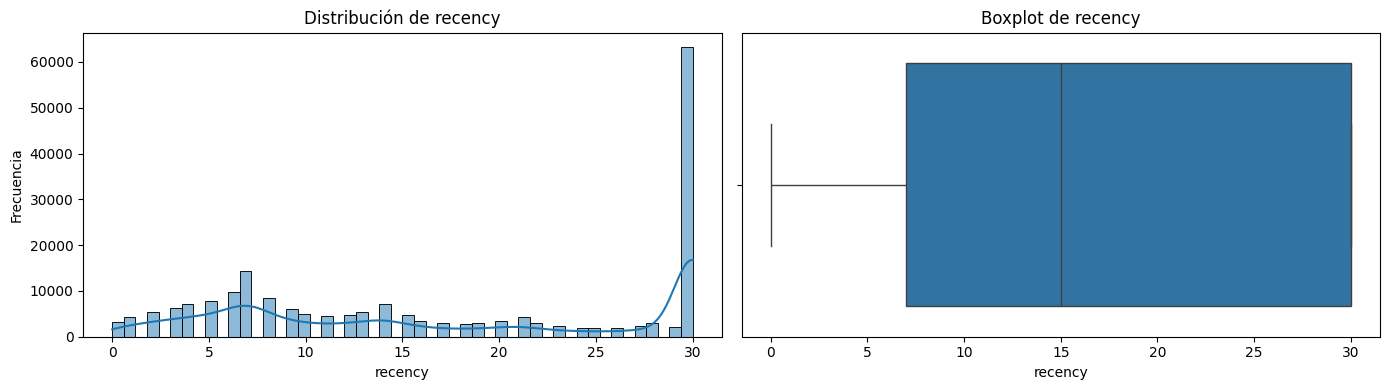

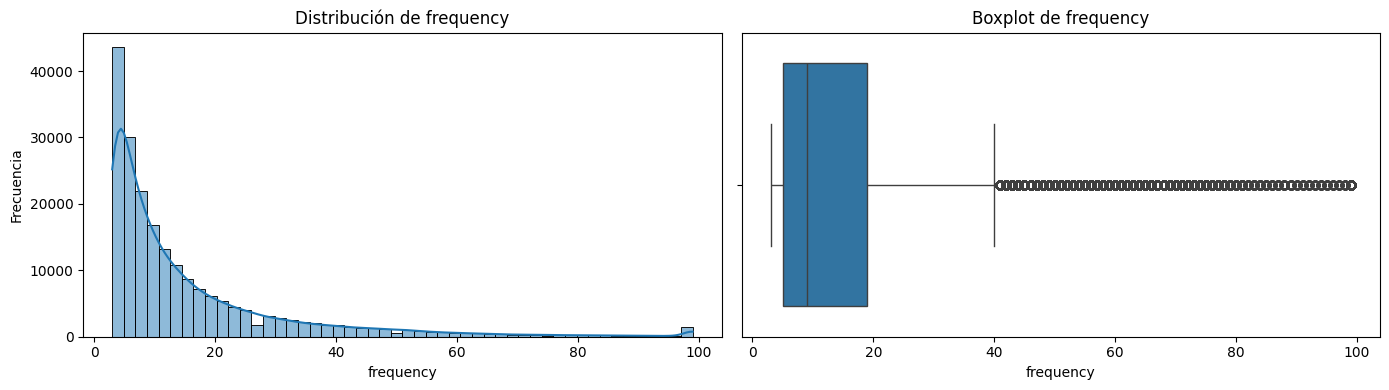

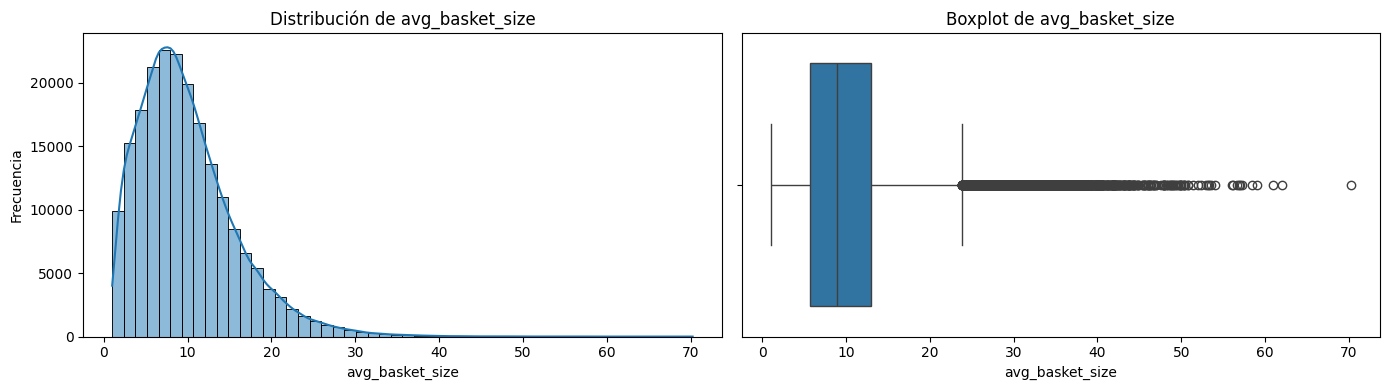

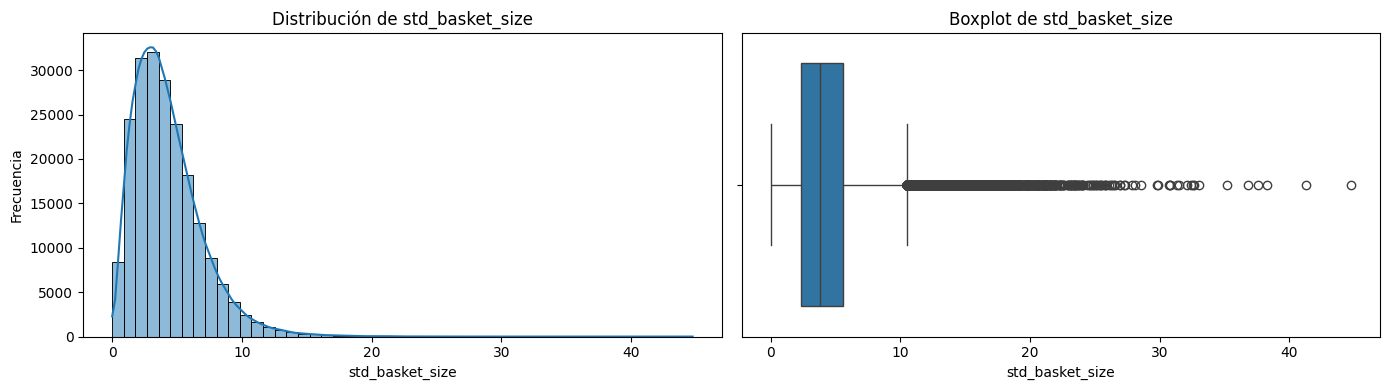

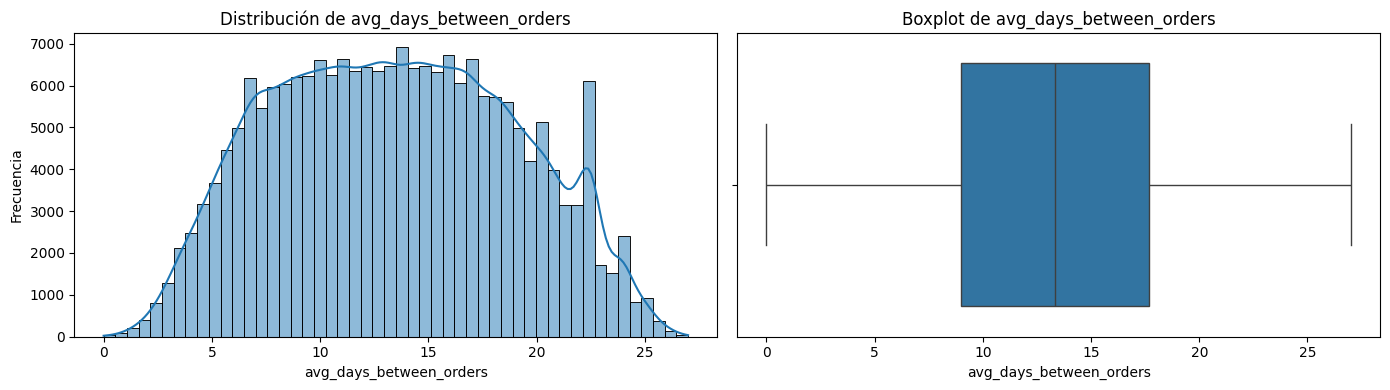

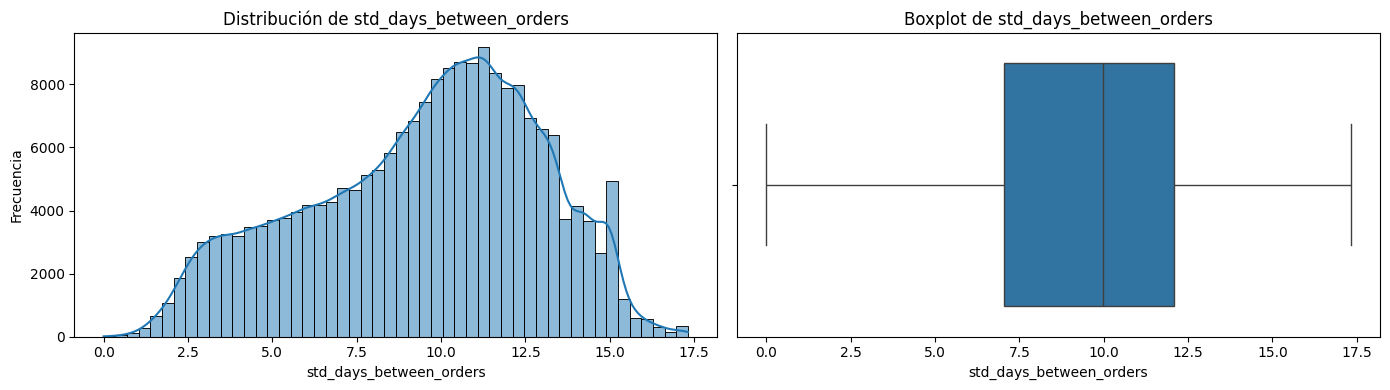

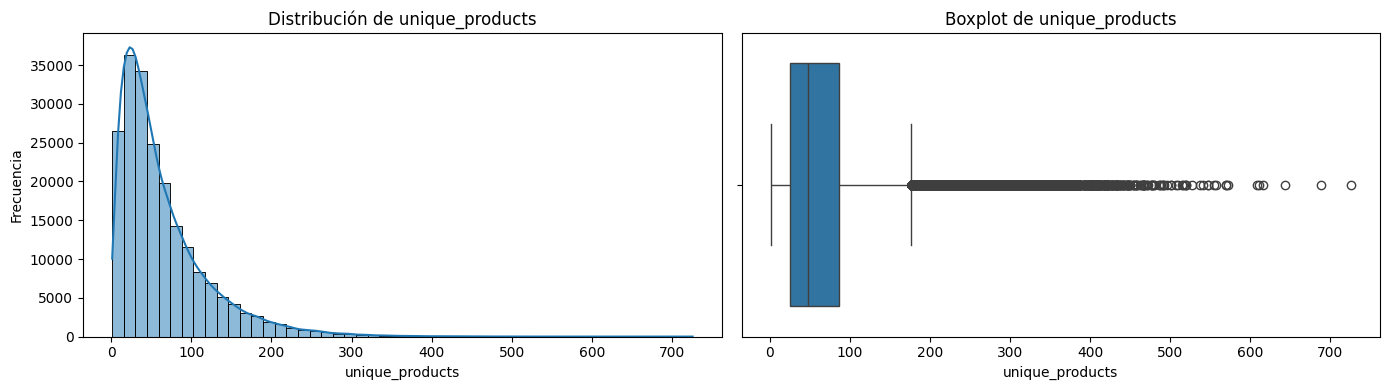

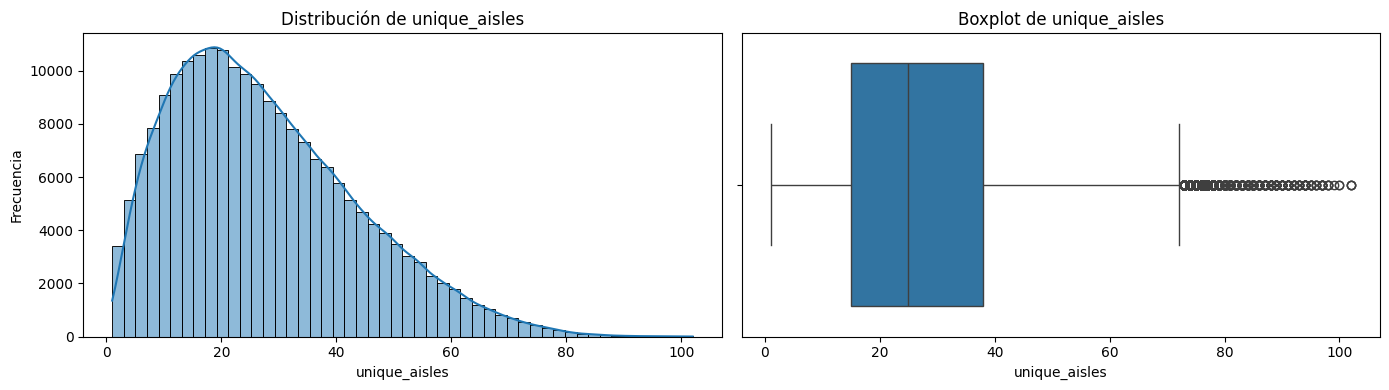

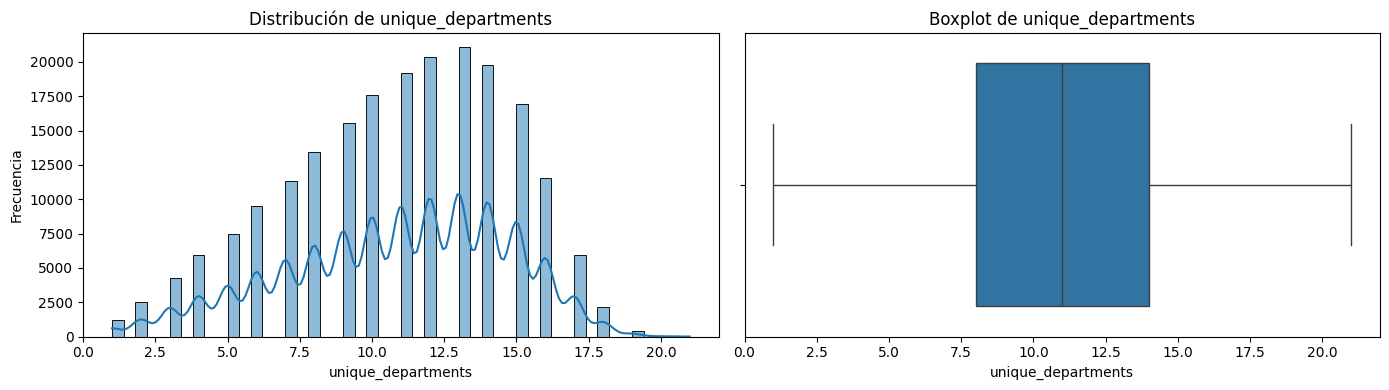

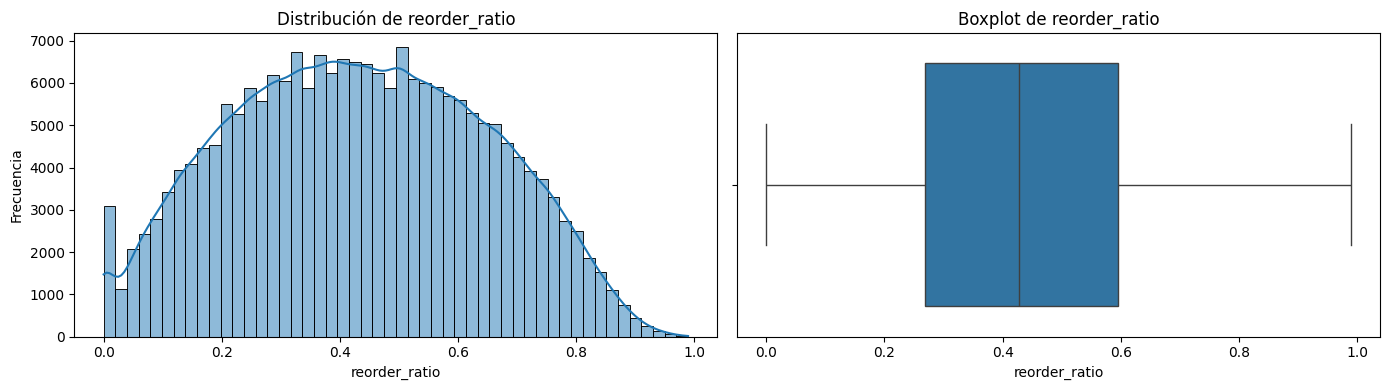

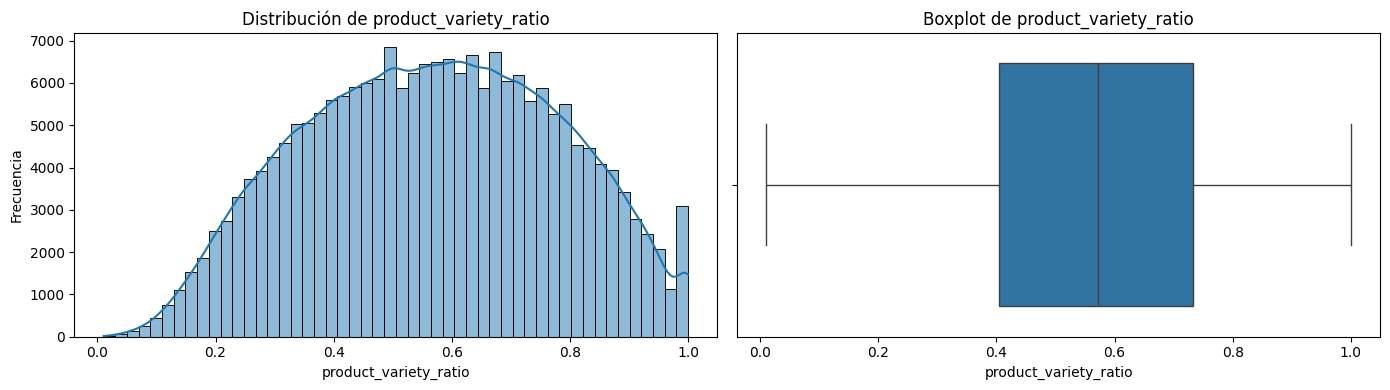

,variable,min,q1,median,mean,q3,max,std,skewness,outliers_iqr_pct,unique_values
0,frequency,3.00,5.000,9.000,15.590,19.000,99.000,16.655,2.400,8.252,97
1,unique_products,1.00,25.000,48.000,64.536,86.000,726.000,56.592,1.921,5.153,493
2,std_basket_size,0.00,2.345,3.782,4.266,5.610,44.747,2.675,1.498,2.744,80678
3,avg_basket_size,1.00,5.741,8.933,9.952,13.000,70.250,5.864,1.230,2.692,18929
4,unique_aisles,1.00,15.000,25.000,27.784,38.000,102.000,16.112,0.714,0.874,101
5,unique_departments,1.00,8.000,11.000,10.828,14.000,21.000,3.792,-0.378,0.000,21
6,std_days_between_orders,0.00,7.029,9.977,9.479,12.067,17.321,3.430,-0.356,0.000,97731
7,avg_days_between_orders,0.00,9.000,13.320,13.429,17.688,27.000,5.496,0.075,0.000,8615
8,recency,0.00,7.000,15.000,17.062,30.000,30.000,10.672,0.037,0.000,31
9,product_variety_ratio,0.01,0.404,0.571,0.568,0.732,1.000,0.212,-0.035,0.000,31280


In [3]:
instacart = pd.read_csv(
    "../../extended_datasets/instacart_model_extended.csv"
)

resumen_instacart = analizar_distribuciones(
    df=instacart,
    id_columns=["user_id"]
)

display(
    resumen_instacart.round(3)
)

In [ ]:
hym = pd.read_csv(
    "../../extended_datasets/hym_model_extended.csv"
)

resumen_hym = analizar_distribuciones(
    df=hym,
    id_columns=["customer_id"]
)

display(
    resumen_hym.round(3)
)